# Iteration Zero — Baseline Model & Data Exploration
**Project:** Automated Vehicle Damage Classification for Motor Insurance Claims  
**Dataset:** CarDD (Car Damage Detection) — 4,000 images, 6 classes: Dent, Scratch, Crack, Glass Shatter, Lamp Broken, Tire Flat

**Goal of this notebook:** confirm that the data contains a learnable signal, using deliberately simple models on raw pixels — no CNN yet. That comes later, in Iteration 2.

**How this notebook is organised.** Every cell does one small thing and shows an output, so each intermediate result can be inspected before moving on.

**What changed compared to earlier runs:** the test set is now **balanced**: it has the same number of crops from every damage category. The classes in CarDD are very unbalanced (far more scratches and dents than flat tires), so with a normal random split a model that simply always answers "scratch" already scores high. With a balanced test set, every class counts equally and that trick no longer works. The model is still k-NN, so the effect of the balanced test set can be seen on its own. Other models come in a later step.

Resized crops are **saved to disk** the first time they are made, so later runs load them instead of cropping and resizing every photo again.

**Before running:** download CarDD and update the `CARDD_ROOT` path in Step 2.

## History: earlier runs

| Run | Setup | Accuracy | Test set |
|---|---|---|---|
| A | Whole photo resized to 32×32, one (dominant) label per photo, k-NN | 39.4% | Skewed (stratified random split) |
| B | Cropped to each bounding box, one label per damage, 32×32, k-NN | 45.7% | Skewed (stratified random split) |

In both runs the test set had the same class balance as the data, so about 41% of it was "scratch". A model that always answers "scratch" would already score 41.1%, which made the accuracy look better than the model really was. That is why this version uses a **balanced test set**. Because the test set is different, the accuracies below are **not directly comparable** to runs A and B.

## Step 0 — Download the dataset (do this once, outside the notebook)

**Recommended: Kaggle mirror (instant, no waiting)**
1. Create a free Kaggle account if you don't have one: https://www.kaggle.com
2. Go to https://www.kaggle.com/datasets/issamjebnouni/cardd
3. Click **Download** and unzip it somewhere on your computer.

**Also submit the official licensing form in parallel** (not urgent, but do it soon): https://cardd-ustc.github.io/docs/CarDD_license.pdf — this gets you the authors' own copy and lets you cite the dataset properly.

**Note on folder structure:** the Kaggle mirror's actual layout is flatter than CarDD's official paper describes — it looks like this:
```
archive (1)/
  train/          <- images
  val/            <- images
  test/           <- images
  train.json      <- annotations for train/
  val.json        <- annotations for val/
  test.json       <- annotations for test/
  image_info.xlsx
```
The config cell below (Step 2) is already set up to detect this layout automatically, as well as the original paper's layout, in case yours looks different.

## Step 1 — Import the libraries

In [1]:
# Run this once if the libraries are not installed yet:
# !pip install pycocotools scikit-learn matplotlib pillow numpy pandas

import glob
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import sklearn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

from pycocotools.coco import COCO

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.3.3 | pandas 2.3.3 | scikit-learn 1.9.1


## Step 2 — Configuration

Point `CARDD_ROOT` to the folder that directly contains `train.json`, `val.json`, `test.json` and the `train/`, `val/`, `test/` image folders.

In [2]:
CARDD_ROOT = r"C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)"

print("Dataset folder:", CARDD_ROOT)
print("Folder exists: ", os.path.isdir(CARDD_ROOT))

Dataset folder: C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)
Folder exists:  True


Find the annotation files. Two layouts are supported: `annotations/instances_*.json` (the layout in the CarDD paper) and `train.json` etc. directly in the folder (the Kaggle mirror).

In [3]:
ann_files = sorted(glob.glob(os.path.join(CARDD_ROOT, "annotations", "instances_*.json")))
if not ann_files:
    ann_files = sorted(glob.glob(os.path.join(CARDD_ROOT, "*.json")))

assert ann_files, "No annotation files found: check that CARDD_ROOT is correct."
print("Annotation files found:")
for f in ann_files:
    print(" -", f)

Annotation files found:
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val.json


Link every annotation file to the folder with its images.

In [4]:
def find_image_dir(split_name):
    # Try a few likely folder names, e.g. 'train', 'train2017'
    candidates = [
        os.path.join(CARDD_ROOT, split_name),
        os.path.join(CARDD_ROOT, split_name.replace("2017", "")),
        os.path.join(CARDD_ROOT, split_name + "2017"),
    ]
    return next((d for d in candidates if os.path.isdir(d)), None)

splits = {}   # split name -> (annotation file, image folder)
for ann_file in ann_files:
    split_name = Path(ann_file).stem.replace("instances_", "")
    img_dir = find_image_dir(split_name)
    if img_dir is None:
        raise FileNotFoundError(f"No image folder found for split '{split_name}'")
    splits[split_name] = (ann_file, img_dir)
    print(f"{split_name:>6}: {os.path.basename(ann_file)}  ->  {img_dir}")

  test: test.json  ->  C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test
 train: train.json  ->  C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train
   val: val.json  ->  C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val


## Step 3 — Load the annotations

All splits (train/val/test) are combined into one pool. This notebook makes its own train/test split later (Step 7), so the original split boundaries are not needed.

First, find every image file on disk, so each annotation can be matched to its photo.

In [5]:
def build_filename_index(root_dir):
    # Map every image file name under root_dir (including subfolders) to its full path
    index = {}
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                index[fname] = os.path.join(dirpath, fname)
    return index

filename_indexes = {}
for split_name, (_, img_dir) in splits.items():
    filename_indexes[split_name] = build_filename_index(img_dir)
    print(f"{split_name:>6}: {len(filename_indexes[split_name])} image files on disk")

  test: 374 image files on disk
 train: 2816 image files on disk
   val: 810 image files on disk


Read the annotation files with `pycocotools`.

In [6]:
cocos = {}
for split_name, (ann_file, _) in splits.items():
    cocos[split_name] = COCO(ann_file)

for split_name, coco in cocos.items():
    print(f"{split_name:>6}: {len(coco.imgs)} images, {len(coco.anns)} annotated damages")

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
loading annotations into memory...
Done (t=0.23s)
creating index...
index created!
  test: 374 images, 785 annotated damages
 train: 2816 images, 6211 annotated damages
   val: 810 images, 1744 annotated damages


The damage categories:

In [7]:
cat_id_to_name = {}
for coco in cocos.values():
    cat_id_to_name.update({c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())})
cat_id_to_name

{1: 'dent',
 2: 'scratch',
 3: 'crack',
 4: 'glass shatter',
 5: 'lamp broken',
 6: 'tire flat'}

One table with every image and where it is on disk. Images that are listed in the annotations but missing on disk are dropped.

In [8]:
image_rows = []
for split_name, coco in cocos.items():
    index = filename_indexes[split_name]
    for img_id, info in coco.imgs.items():
        image_rows.append({
            "split": split_name,
            "image_id": img_id,
            "file_name": info["file_name"],
            "full_path": index.get(os.path.basename(info["file_name"])),
        })
images_df = pd.DataFrame(image_rows)

print(f"Images in the annotations: {len(images_df)}")
print(f"Not found on disk:         {images_df['full_path'].isna().sum()}")
images_df = images_df.dropna(subset=["full_path"]).reset_index(drop=True)
images_df.head()

Images in the annotations: 4000
Not found on disk:         0


,split,image_id,file_name,full_path
0,test,12,000012.jpg,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
1,test,15,000015.jpg,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
2,test,23,000023.jpg,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
3,test,33,000033.jpg,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
4,test,40,000040.jpg,C:\Users\user\Documents\Semester 4 ProfTask\Pe...


One table with every annotated damage: its category and its bounding box `[x, y, width, height]`. Each damage gets a unique `crop_id`, which is used later as the file name of its saved crop.

In [9]:
ann_rows = []
for split_name, coco in cocos.items():
    for ann in coco.anns.values():
        ann_rows.append({
            "crop_id": f"{split_name}_{ann['id']}",
            "split": split_name,
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "area": ann.get("area", 0),
            "bbox": ann.get("bbox"),
        })
anns_df = pd.DataFrame(ann_rows)
anns_df["category_name"] = anns_df["category_id"].map(cat_id_to_name)

# Keep only damages whose photo was found on disk, and add the photo's location
anns_df = anns_df.merge(images_df[["split", "image_id", "full_path"]], on=["split", "image_id"], how="inner")
print(f"Annotated damages with a photo on disk: {len(anns_df)}")
anns_df.head()

Annotated damages with a photo on disk: 8740


,crop_id,split,image_id,category_id,area,bbox,category_name,full_path
0,test_1,test,12,6,85783.0,"[32.61, 221.06, 331.72, 332.82]",tire flat,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
1,test_2,test,12,6,20953.0,"[687.22, 367.63, 174.13, 150.98]",tire flat,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
2,test_3,test,15,2,8217.0,"[336.28, 496.65, 213.83, 76.59]",scratch,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
3,test_4,test,23,1,12813.0,"[341.78, 174.47, 158.81, 103.79]",dent,C:\Users\user\Documents\Semester 4 ProfTask\Pe...
4,test_5,test,23,2,2768.0,"[539.73, 338.67, 79.79, 69.42]",scratch,C:\Users\user\Documents\Semester 4 ProfTask\Pe...


## Step 4 — Exploratory Data Analysis (EDA)

How many damages are there per category?

category_name
scratch          3595
dent             2543
crack             898
lamp broken       704
glass shatter     681
tire flat         319
Name: count, dtype: int64


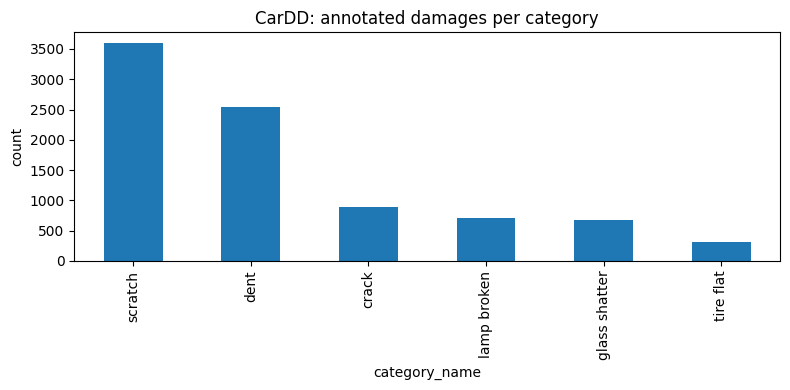

In [10]:
instance_counts = anns_df["category_name"].value_counts()
print(instance_counts)

instance_counts.plot(kind="bar", figsize=(8, 4), title="CarDD: annotated damages per category")
plt.ylabel("count")
plt.tight_layout()
plt.show()

How many photos contain more than one damage? This is why every damage is used as its own example, instead of one label per photo.

In [11]:
damages_per_image = anns_df.groupby(["split", "image_id"]).size()
print(f"Photos with exactly 1 damage:    {(damages_per_image == 1).sum()}")
print(f"Photos with more than 1 damage:  {(damages_per_image > 1).sum()}")

Photos with exactly 1 damage:    1816
Photos with more than 1 damage:  2184


How large are the bounding boxes? Small boxes explain why resizing the whole photo lost so much detail.

In [12]:
anns_df["bbox_width"] = anns_df["bbox"].apply(lambda b: b[2] if b is not None else np.nan)
anns_df["bbox_height"] = anns_df["bbox"].apply(lambda b: b[3] if b is not None else np.nan)
anns_df.groupby("category_name")[["bbox_width", "bbox_height"]].median().round(0)

,bbox_width,bbox_height
category_name,,
crack,87.0,84.0
dent,256.0,220.0
glass shatter,888.0,537.0
lamp broken,435.0,271.0
scratch,247.0,166.0
tire flat,478.0,491.0


One example photo with its annotated damages drawn on it, to check that the boxes are in the right place.

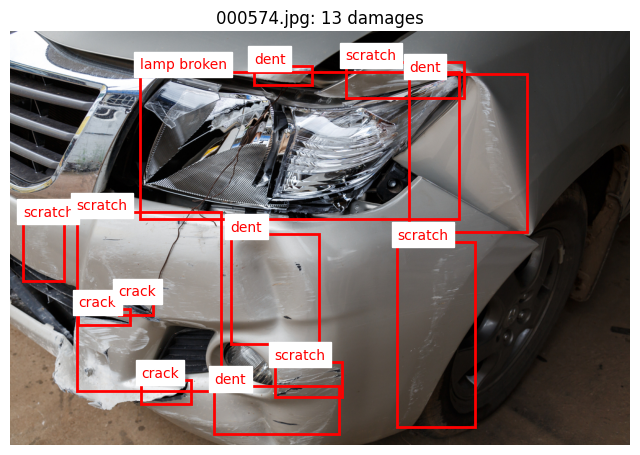

In [13]:
example_image = anns_df.groupby(["split", "image_id"]).size().idxmax()   # the photo with the most damages
example_anns = anns_df[(anns_df["split"] == example_image[0]) & (anns_df["image_id"] == example_image[1])]

img = Image.open(example_anns["full_path"].iloc[0]).convert("RGB")
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img)
for _, ann in example_anns.iterrows():
    x, y, w, h = ann["bbox"]
    ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2))
    ax.text(x, y - 5, ann["category_name"], color="red", fontsize=10, backgroundcolor="white")
ax.set_title(f"{os.path.basename(example_anns['full_path'].iloc[0])}: {len(example_anns)} damages")
ax.axis("off")
plt.show()

## Step 5 — One example per damage

Every annotated bounding box becomes its own example with its own label. A photo with a dent and a scratch gives two examples. Damages without a bounding box cannot be cropped and are left out.

In [14]:
crops_df = anns_df[anns_df["bbox"].notna()].reset_index(drop=True)

print(f"Damages to crop: {len(crops_df)}")
print(crops_df["category_name"].value_counts())

Damages to crop: 8740
category_name
scratch          3595
dent             2543
crack             898
lamp broken       704
glass shatter     681
tire flat         319
Name: count, dtype: int64


## Step 6 — Crop, resize and save the damages

Each damage is cut out of its photo using its bounding box, resized to a fixed size and turned into a row of numbers. The steps are first checked on **one example**, then run for all damages.

The size is set here. It is kept at 32×32, the same as the earlier runs, so the only change compared to those runs is the balanced test set.

In [15]:
IMG_SIZE = (32, 32)
SAVE_ROOT = "resized_crops"   # crops are saved in SAVE_ROOT/<size>/<category>/<crop_id>.png

print(f"Image size: {IMG_SIZE}, crops saved under: {os.path.abspath(SAVE_ROOT)}")

Image size: (32, 32), crops saved under: C:\Users\user\Documents\Semester 4 ProfTask\Personal\resized_crops


Cut out one damage using its bounding box. On the left the original photo with the box, on the right the crop.

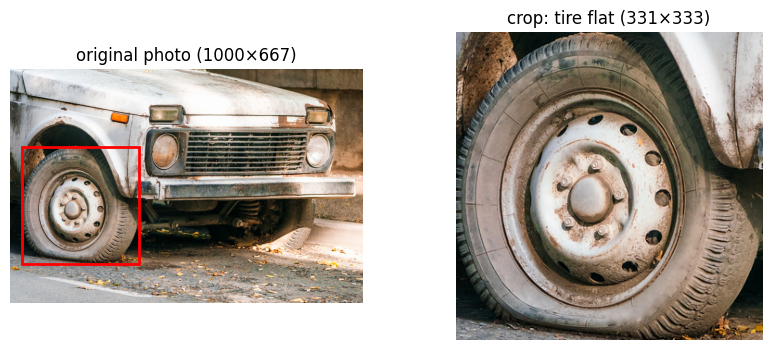

In [16]:
def crop_to_bbox(img, bbox):
    # COCO bbox is [x, y, width, height]; clip to the image in case the box runs slightly outside it
    x, y, w, h = bbox
    left, top = max(0, x), max(0, y)
    right, bottom = min(img.width, x + w), min(img.height, y + h)
    return img.crop((left, top, right, bottom))

example = crops_df.iloc[0]
example_img = Image.open(example["full_path"]).convert("RGB")
example_crop = crop_to_bbox(example_img, example["bbox"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(example_img)
x, y, w, h = example["bbox"]
axes[0].add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"original photo ({example_img.width}×{example_img.height})")
axes[1].imshow(example_crop)
axes[1].set_title(f"crop: {example['category_name']} ({example_crop.width}×{example_crop.height})")
for ax in axes:
    ax.axis("off")
plt.show()

Resize that crop and turn it into a row of numbers: width × height × 3 colours, scaled from 0–255 to 0–1.

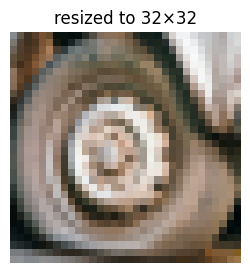

Numbers per crop: 3072  (= 32 × 32 × 3)
Smallest value: 0.00, largest value: 0.98


In [17]:
example_resized = example_crop.resize(IMG_SIZE)
example_row = np.asarray(example_resized, dtype=np.float32).flatten() / 255.0

plt.figure(figsize=(3, 3))
plt.imshow(example_resized)
plt.title(f"resized to {IMG_SIZE[0]}×{IMG_SIZE[1]}")
plt.axis("off")
plt.show()

print(f"Numbers per crop: {example_row.shape[0]}  (= {IMG_SIZE[0]} × {IMG_SIZE[1]} × 3)")
print(f"Smallest value: {example_row.min():.2f}, largest value: {example_row.max():.2f}")

The same steps as one function that also **saves** the resized crop. If the file already exists from an earlier run, it is loaded instead of cropping the photo again. Checked on the same example:

In [18]:
def crop_path(row, size):
    return os.path.join(SAVE_ROOT, f"{size[0]}x{size[1]}", row["category_name"], f"{row['crop_id']}.png")

def load_crop(row, size):
    path = crop_path(row, size)
    if os.path.exists(path):
        resized = Image.open(path).convert("RGB")                 # made in an earlier run
    else:
        img = Image.open(row["full_path"]).convert("RGB")
        resized = crop_to_bbox(img, row["bbox"]).resize(size)     # crop and resize once...
        os.makedirs(os.path.dirname(path), exist_ok=True)
        resized.save(path)                                        # ...and save for next time
    return np.asarray(resized, dtype=np.float32).flatten() / 255.0

print("Saved to:", crop_path(example, IMG_SIZE))
print("Same numbers as above:", np.allclose(load_crop(example, IMG_SIZE), example_row))

Saved to: resized_crops\32x32\tire flat\test_1.png
Same numbers as above: True


A few crops per category, to check by eye that the crops show the damage they are labelled with.

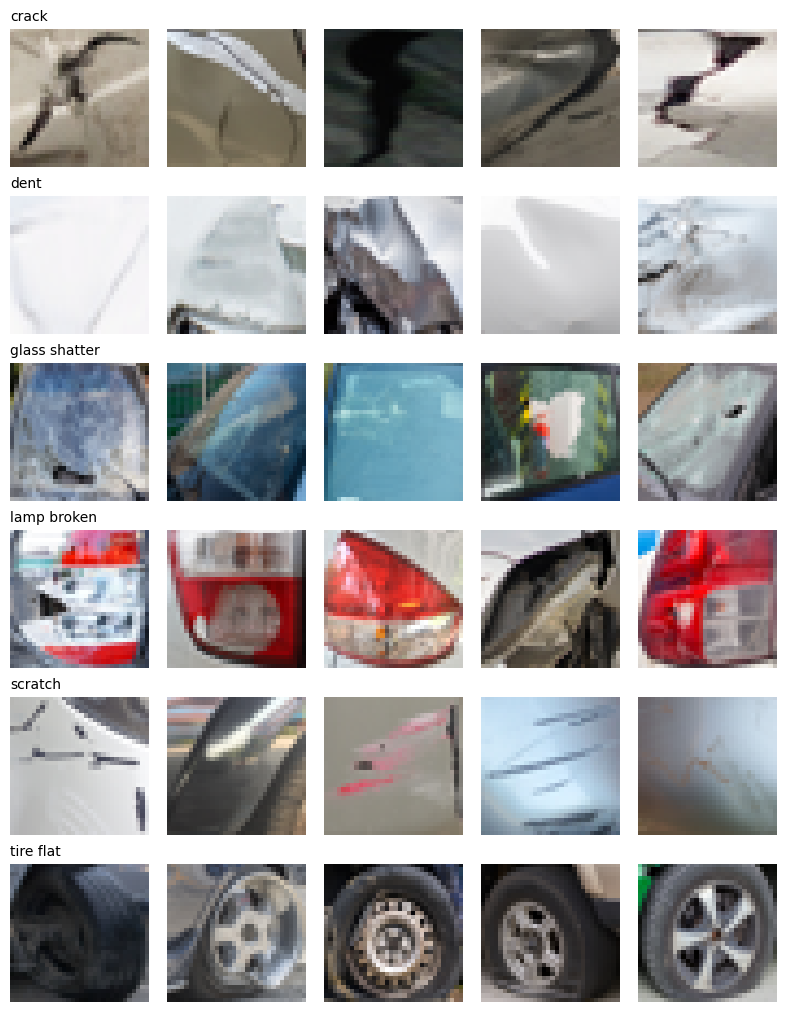

In [19]:
categories = sorted(crops_df["category_name"].unique())
n_examples = 5

fig, axes = plt.subplots(len(categories), n_examples, figsize=(n_examples * 1.6, len(categories) * 1.7))
for r, category in enumerate(categories):
    rows = crops_df[crops_df["category_name"] == category].sample(n_examples, random_state=0)
    for c, (_, row) in enumerate(rows.iterrows()):
        axes[r, c].imshow(load_crop(row, IMG_SIZE).reshape(IMG_SIZE[1], IMG_SIZE[0], 3))
        axes[r, c].axis("off")
    axes[r, 0].set_title(category, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

Now do this for every damage. The first run crops and saves everything; later runs load the saved crops and are much faster.

In [20]:
def build_features(size):
    features, labels, ids = [], [], []
    skipped = 0
    start = time.time()
    total = len(crops_df)
    for i, (_, row) in enumerate(crops_df.iterrows(), start=1):
        try:
            features.append(load_crop(row, size))
            labels.append(row["category_name"])
            ids.append(row["crop_id"])
        except (FileNotFoundError, OSError, ValueError):   # unreadable photo or empty box
            skipped += 1
        if i % 1000 == 0 or i == total:
            print(f"  ...{i}/{total} crops ({time.time() - start:.1f}s, {skipped} skipped)")
    return np.stack(features), np.array(labels), np.array(ids)

X, y, crop_ids = build_features(IMG_SIZE)
print(f"Feature matrix: {X.shape[0]} crops × {X.shape[1]} numbers")

  ...1000/8740 crops (2.0s, 0 skipped)
  ...2000/8740 crops (3.9s, 0 skipped)
  ...3000/8740 crops (5.6s, 0 skipped)
  ...4000/8740 crops (7.3s, 0 skipped)
  ...5000/8740 crops (9.0s, 0 skipped)
  ...6000/8740 crops (10.7s, 0 skipped)
  ...7000/8740 crops (12.1s, 0 skipped)
  ...8000/8740 crops (13.6s, 0 skipped)
  ...8740/8740 crops (14.7s, 0 skipped)
Feature matrix: 8740 crops × 3072 numbers


Check what was saved on disk.

In [21]:
size_dir = os.path.join(SAVE_ROOT, f"{IMG_SIZE[0]}x{IMG_SIZE[1]}")
for category in sorted(os.listdir(size_dir)):
    print(f"{category:>14}: {len(os.listdir(os.path.join(size_dir, category)))} files")

         crack: 898 files
          dent: 2543 files
 glass shatter: 681 files
   lamp broken: 704 files
       scratch: 3595 files
     tire flat: 319 files


## Step 7 — Balanced test set

**The problem.** The categories are very unbalanced. Below is the share of each category in all crops. If the test set had the same shares (a normal random split), a model that **always predicts the largest category** would already be right that often, without learning anything.

In [22]:
shares = pd.Series(y).value_counts(normalize=True)
print((shares * 100).round(1).astype(str) + "%")
print(f"\nAlways predicting '{shares.index[0]}' would score {shares.iloc[0]:.1%} on a normal random test set.")

scratch          41.1%
dent             29.1%
crack            10.3%
lamp broken       8.1%
glass shatter     7.8%
tire flat         3.6%
Name: proportion, dtype: object

Always predicting 'scratch' would score 41.1% on a normal random test set.


**The solution.** The test set gets **the same number of crops from every category**. Then always predicting one category scores only 1 in 6 (16.7%), and the score shows how well the model recognises *every* type of damage.

How many test crops per category? The smallest category limits this: 20% of it is used for testing, and every other category gets the same number.

In [23]:
classes, counts = np.unique(y, return_counts=True)
n_test_per_class = int(counts.min() * 0.2)

print(f"Smallest category: {classes[counts.argmin()]} ({counts.min()} crops)")
print(f"Test crops per category: {n_test_per_class}  (20% of {counts.min()})")

Smallest category: tire flat (319 crops)
Test crops per category: 63  (20% of 319)


Pick that many crops at random from every category. `rng` with a fixed seed (42) makes sure the same crops are picked every time the notebook runs.

In [24]:
rng = np.random.default_rng(42)

test_idx = np.concatenate([
    rng.choice(np.where(y == c)[0], size=n_test_per_class, replace=False)   # random positions of crops of category c
    for c in classes
])
print(f"Test crops picked: {len(test_idx)}  ({n_test_per_class} × {len(classes)} categories)")

Test crops picked: 378  (63 × 6 categories)


Everything that was not picked for the test set goes to the train set.

In [25]:
train_mask = np.ones(len(y), dtype=bool)   # start with everything in train...
train_mask[test_idx] = False               # ...and take the test crops out

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train: {len(y_train)} crops, test: {len(y_test)} crops")
print("No crop in both sets:", len(set(np.where(train_mask)[0]) & set(test_idx)) == 0)

Train: 8362 crops, test: 378 crops
No crop in both sets: True


Crops per category in each set. The **test set is balanced**; the **train set is still unbalanced**, because it contains everything else. That is fine for now: the test set is what decides how fair the score is. Balancing what the model *learns from* is a later step.

In [26]:
pd.DataFrame({"train": pd.Series(y_train).value_counts(),
              "test": pd.Series(y_test).value_counts()})

,train,test
crack,835,63
dent,2480,63
glass shatter,618,63
lamp broken,641,63
scratch,3532,63
tire flat,256,63


## Step 8 — Baselines and evaluation helpers

Two baselines to beat:
- **Random guessing** among 6 classes.
- **Always predicting the largest class.** On a normal random test set this would score about 41% (see Step 7). On the balanced test set it drops to the same level as random guessing, so any score above it is real learning.

In [27]:
random_baseline = 1 / len(classes)
largest_class = pd.Series(y_train).value_counts().idxmax()
majority_baseline = np.mean(y_test == largest_class)

print(f"Random guessing:                  {random_baseline:.1%}")
print(f"Always predict '{largest_class}':  {majority_baseline:.1%}  (on this balanced test set)")

Random guessing:                  16.7%
Always predict 'scratch':  16.7%  (on this balanced test set)


Every experiment is scored the same way:
- **Accuracy:** share of test crops predicted correctly.
- **Balanced accuracy:** the average recall per class, so every class counts equally. With a balanced test set it is the same as accuracy; it is shown anyway, as a check.
- **Classification report** and **confusion matrix** per class.

All scores are collected in `results`, which is shown as one table at the end. When another model is tried later, it is added there, so the models can be compared on the same balanced test set.

In [28]:
results = []

def score(name, y_true, y_pred, train_seconds):
    acc = accuracy_score(y_true, y_pred)
    bal = balanced_accuracy_score(y_true, y_pred)
    results.append({"experiment": name, "accuracy": round(acc, 3),
                    "balanced accuracy": round(bal, 3), "training time (s)": round(train_seconds, 1)})
    print(f"{name}\n  accuracy:          {acc:.3f}\n  balanced accuracy: {bal:.3f}")

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=classes, normalize="true")   # each row sums to 1
    fig, ax = plt.subplots(figsize=(7, 7))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=45, cmap="Reds", values_format=".2f")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

print("Helpers ready. Results so far:", results)

Helpers ready. Results so far: []


## Experiment 1 — k-NN, 32×32

The same model as runs A and B (k-NN with 5 neighbours, no tuning). The only change is the balanced test set.

In [29]:
knn = KNeighborsClassifier(n_neighbors=5)

start = time.time()
knn.fit(X_train, y_train)
train_seconds_1 = time.time() - start
print(f"Training took {train_seconds_1:.1f}s")

Training took 0.1s


In [30]:
y_pred_1 = knn.predict(X_test)
score("1: k-NN, 32×32", y_test, y_pred_1, train_seconds_1)

1: k-NN, 32×32
  accuracy:          0.280
  balanced accuracy: 0.280


In [31]:
print(classification_report(y_test, y_pred_1, zero_division=0))

               precision    recall  f1-score   support

        crack       0.56      0.14      0.23        63
         dent       0.19      0.35      0.25        63
glass shatter       0.56      0.08      0.14        63
  lamp broken       1.00      0.02      0.03        63
      scratch       0.23      0.81      0.36        63
    tire flat       1.00      0.29      0.44        63

     accuracy                           0.28       378
    macro avg       0.59      0.28      0.24       378
 weighted avg       0.59      0.28      0.24       378



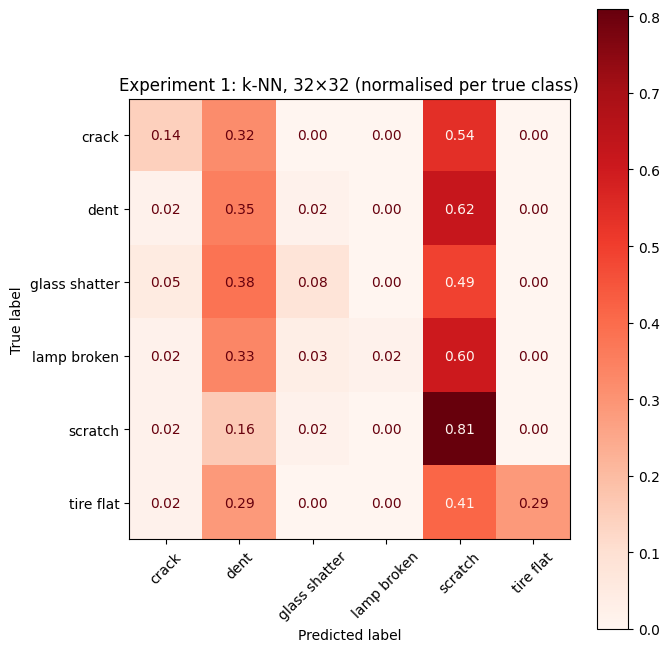

In [32]:
plot_confusion(y_test, y_pred_1, "Experiment 1: k-NN, 32×32 (normalised per true class)")

**Observations:** ___

## Experiment 2 — SVM, 32×32

Same crops, same balanced test set, same train set as Experiment 1. The **only change is the model**: a support vector machine (RBF kernel, default settings, no tuning). The pixels are already scaled to 0–1, so no extra scaling is needed.

In [33]:
from sklearn.svm import SVC

In [34]:
svm = SVC(kernel="rbf", C=1.0, gamma="scale", verbose=True) #This line creates the model
#A low C allows some mistakes and gives a smoother boundary.
#how far the influence of one crop reaches.

start = time.time()
svm.fit(X_train, y_train)
train_seconds_2 = time.time() - start
print(f"Training took {train_seconds_2:.1f}s")

[LibSVM]Training took 7357.9s


In [35]:
y_pred_2 = svm.predict(X_test)
score("2: SVM (RBF), 32×32", y_test, y_pred_2, train_seconds_2)

2: SVM (RBF), 32×32
  accuracy:          0.481
  balanced accuracy: 0.481


In [36]:
print(classification_report(y_test, y_pred_2, zero_division=0))

               precision    recall  f1-score   support

        crack       0.50      0.13      0.20        63
         dent       0.42      0.48      0.45        63
glass shatter       0.83      0.32      0.46        63
  lamp broken       0.86      0.49      0.63        63
      scratch       0.28      0.84      0.42        63
    tire flat       0.98      0.63      0.77        63

     accuracy                           0.48       378
    macro avg       0.65      0.48      0.49       378
 weighted avg       0.65      0.48      0.49       378



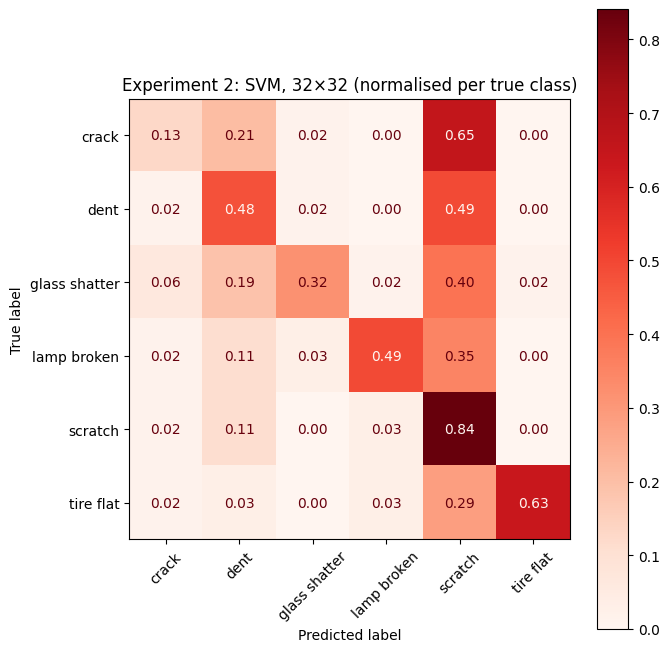

In [37]:
plot_confusion(y_test, y_pred_2, "Experiment 2: SVM, 32×32 (normalised per true class)")

**Observations:** ## Experiment 2 — Observations

The SVM scores **48.1%** on the balanced test set, against 28.0% for k-NN and 16.7% for random guessing. The test set and train set are the same as in Experiment 1, so the improvement comes from the model alone.

The biggest improvements are for lamp broken (recall 0.02 → 0.49), tire flat (0.29 → 0.63) and glass shatter (0.08 → 0.32). Crack is still almost never recognised (recall 0.13); most cracks are predicted as scratch (65%).

Scratch is still the model's default answer when it is unsure: scratch has the highest recall (0.84) but the lowest precision (0.28). Training took 7,358 s (about 2 hours), which is far slower than k-NN (0.2 s).

## Experiment 3 — SVM with balanced class weights, 32×32

The train set is still unbalanced (3,532 scratch against 256 tire flat). `class_weight="balanced"` makes mistakes on rare categories count more during training. The test set and the crops are unchanged.

In [44]:
svm_bal = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced") #This line creates the non linear model
#A low C allows some mistakes and gives a smoother boundary.
#how far the influence of one crop reaches.
#A mistake on a rare category is made more expensive since we have the "balanced"

start = time.time()
svm_bal.fit(X_train, y_train)
train_seconds_3 = time.time() - start
print(f"Training took {train_seconds_3:.1f}s")

Training took 250.9s


In [45]:
y_pred_3 = svm_bal.predict(X_test)
score("3: SVM (RBF, balanced weights), 32×32", y_test, y_pred_3, train_seconds_3)

3: SVM (RBF, balanced weights), 32×32
  accuracy:          0.624
  balanced accuracy: 0.624


In [46]:
print(classification_report(y_test, y_pred_3, zero_division=0))

               precision    recall  f1-score   support

        crack       0.51      0.46      0.48        63
         dent       0.56      0.54      0.55        63
glass shatter       0.64      0.68      0.66        63
  lamp broken       0.77      0.68      0.72        63
      scratch       0.45      0.60      0.51        63
    tire flat       0.94      0.78      0.85        63

     accuracy                           0.62       378
    macro avg       0.64      0.62      0.63       378
 weighted avg       0.64      0.62      0.63       378



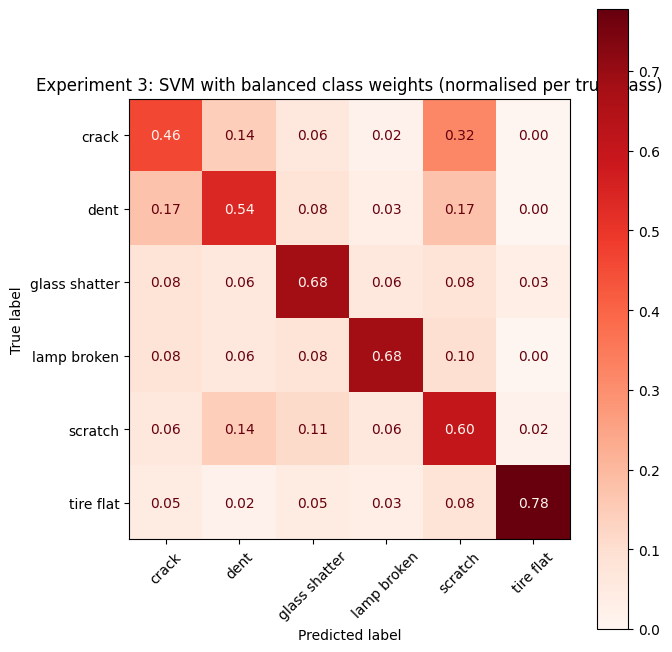

In [47]:
plot_confusion(y_test, y_pred_3, "Experiment 3: SVM with balanced class weights (normalised per true class)")

**Observations:** ___

## Step 9 — Results

One row per model. When another model is tried later, it appears here as a new row.

In [42]:
pd.DataFrame(results).set_index("experiment")

,accuracy,balanced accuracy,training time (s)
experiment,,,
"1: k-NN, 32×32",0.280,0.280,0.1
"2: SVM (RBF), 32×32",0.481,0.481,7357.9
"3: SVM (RBF, balanced weights), 32×32",0.624,0.624,247.4


## Step 10 — Conclusion

**Earlier runs (unbalanced test set):** the whole-photo version reached 39.4% and the cropped version 45.7%, but a model that always predicts "scratch" would already have scored 41.1% on that test set. These scores are therefore not comparable with the runs below, which use a **balanced test set**: 63 crops of every category (378 in total), so every damage type counts equally. Random guessing and always predicting one class both score 16.7% on it.

**Three experiments, one change at a time.** The crops (32×32), the train set and the test set are the same in all three.

| Experiment | Change | Accuracy | Training time |
|---|---|---|---|
| 1: k-NN | starting point | 28.0% | 0.2 s |
| 2: SVM (RBF) | different model | 48.1% | 7,358 s |
| 3: SVM (RBF), balanced class weights | rare categories count more | **62.4%** | about 250 s |

- **Experiment 1 (k-NN, 28.0%):** about 1.7 times better than guessing, so the images contain a learnable signal. But the model predicts "scratch" or "dent" for almost everything, because k-NN compares raw pixels and the 5 nearest neighbours are usually scratches or dents (72% of the train set). Crack (recall 0.14), glass shatter (0.08) and lamp broken (0.02) are hardly recognised.
- **Experiment 2 (SVM, 48.1%):** changing only the model improved the score by 20 percentage points. The rare categories improved the most: lamp broken 0.02 → 0.49, tire flat 0.29 → 0.63, glass shatter 0.08 → 0.32. But crack stayed at 0.13 and scratch remained the default answer (recall 0.84, precision only 0.28).
- **Experiment 3 (SVM with balanced class weights, 62.4%):** the train set is still unbalanced, but a mistake on a rare category now counts more during training. This improved the score by another 14 percentage points. Recall is now 0.46 for crack, 0.54 for dent, 0.68 for glass shatter, 0.68 for lamp broken and 0.78 for tire flat. Scratch recall dropped from 0.84 to 0.60, but its precision rose from 0.28 to 0.45: the model no longer uses scratch as its default answer.
- **What this shows:** the weak k-NN result was caused by both the model and the imbalance in the train set. Both changes helped, and the second one helped more than I expected. The best model is about 3.7 times better than random guessing, but it is still wrong in about 4 out of 10 cases. Crack (0.46) and scratch (precision 0.45) are the weakest points.
- **Limits:** the models still see only raw pixels, so they cannot recognise shapes such as a crack or a shattered window. Only default settings were used (no tuning). The test set has 378 crops, so small differences should not be over-interpreted.
- **Next step:** try larger crops (64×64) with the balanced SVM, now that the SVM handles long feature vectors. If tuning is done, use a validation set and not the test set. After that, a CNN with transfer learning in Iteration 2 should recognise shapes better.